In [78]:
# importing required libriaries
import cv2
import matplotlib.pyplot as plt
from skimage.segmentation import active_contour
import numpy as np

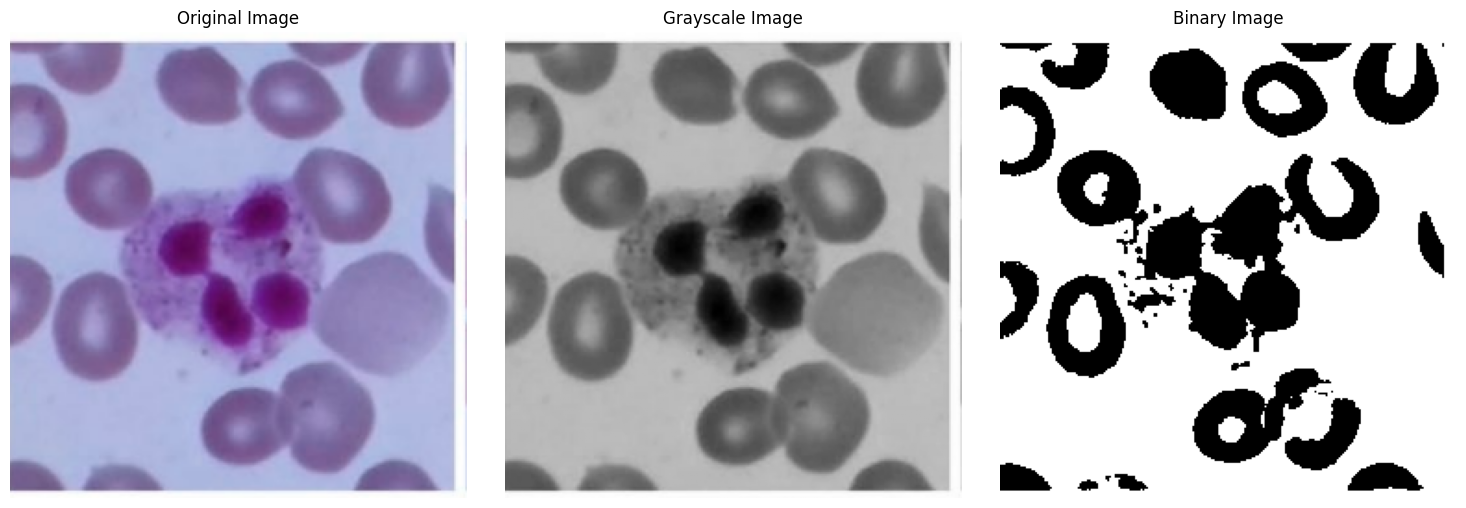

In [79]:
# prining the image in og, grayscale, binary
img = cv2.imread('P2.png')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
binary = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)[1]

fig, axis = plt.subplots(1, 3, figsize=(15, 5))

axis[0].imshow(img)
axis[0].set_title('Original Image')
axis[0].axis('off')

axis[1].imshow(gray, cmap='gray')
axis[1].set_title('Grayscale Image')
axis[1].axis('off')

axis[2].imshow(binary, cmap='gray')
axis[2].set_title('Binary Image')
axis[2].axis('off')

plt.tight_layout()
plt.show()


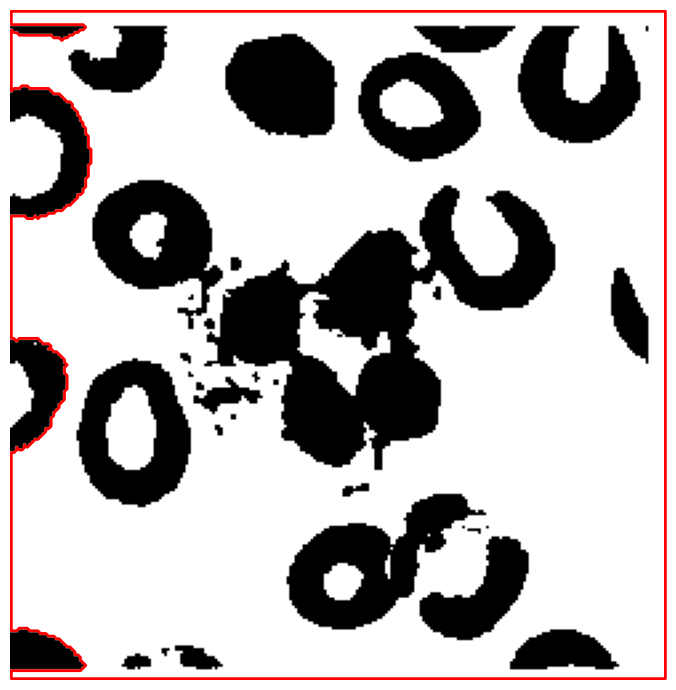

In [80]:
# making the init contour
contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
largest_contour = max(contours, key=cv2.contourArea)
init = np.squeeze(largest_contour).astype(float)

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(binary, cmap='gray')
ax.plot(init[:, 0], init[:, 1], 'r-', linewidth=2)
ax.axis('off')
plt.tight_layout()
plt.show()

In [81]:
# a fn to calucaute the internal energy
def calculate_internal_energy(snake, alpha, beta):
    n = len(snake)
    energy = np.zeros(n)
    
    for i in range(n):
        prev = snake[i - 1]
        curr = snake[i]
        next = snake[(i + 1) % n]
        
        elasticity = alpha * np.sum((curr - prev) ** 2)
        
        curvature = curr - 2 * prev + snake[(i - 2) % n]
        stiffness = beta * np.sum(curvature ** 2)
        
        energy[i] = elasticity + stiffness
    
    return energy

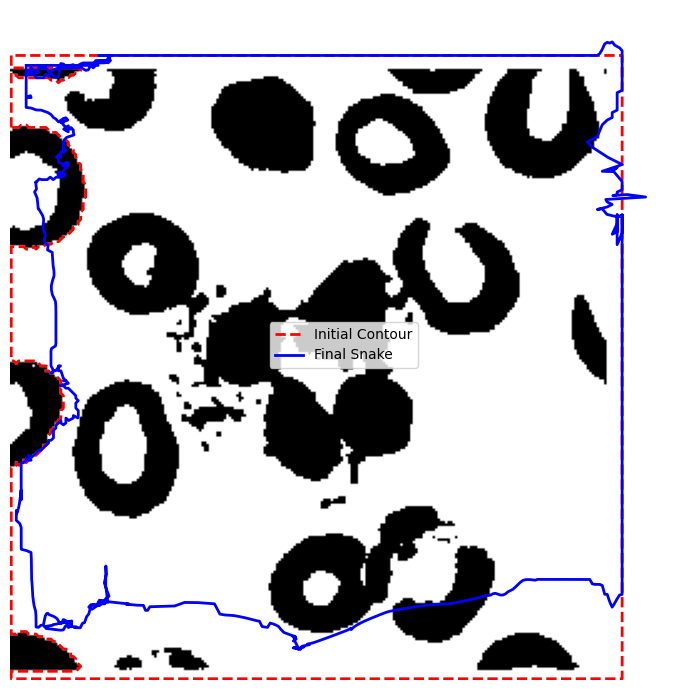

In [82]:
# running the active contou
s = np.linspace(0, 2 * np.pi, len(init))
snake = active_contour(binary, init, alpha=0.3, beta=10, gamma=0.001, w_line=-5, w_edge=0)

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(binary, cmap='gray')
ax.plot(init[:, 0], init[:, 1], 'r--', linewidth=2, label='Initial Contour')
ax.plot(snake[:, 0], snake[:, 1], 'b-', linewidth=2, label='Final Snake')
ax.legend()
ax.axis('off')
plt.tight_layout()
plt.show()

# a few tests for my self to find a good performing params

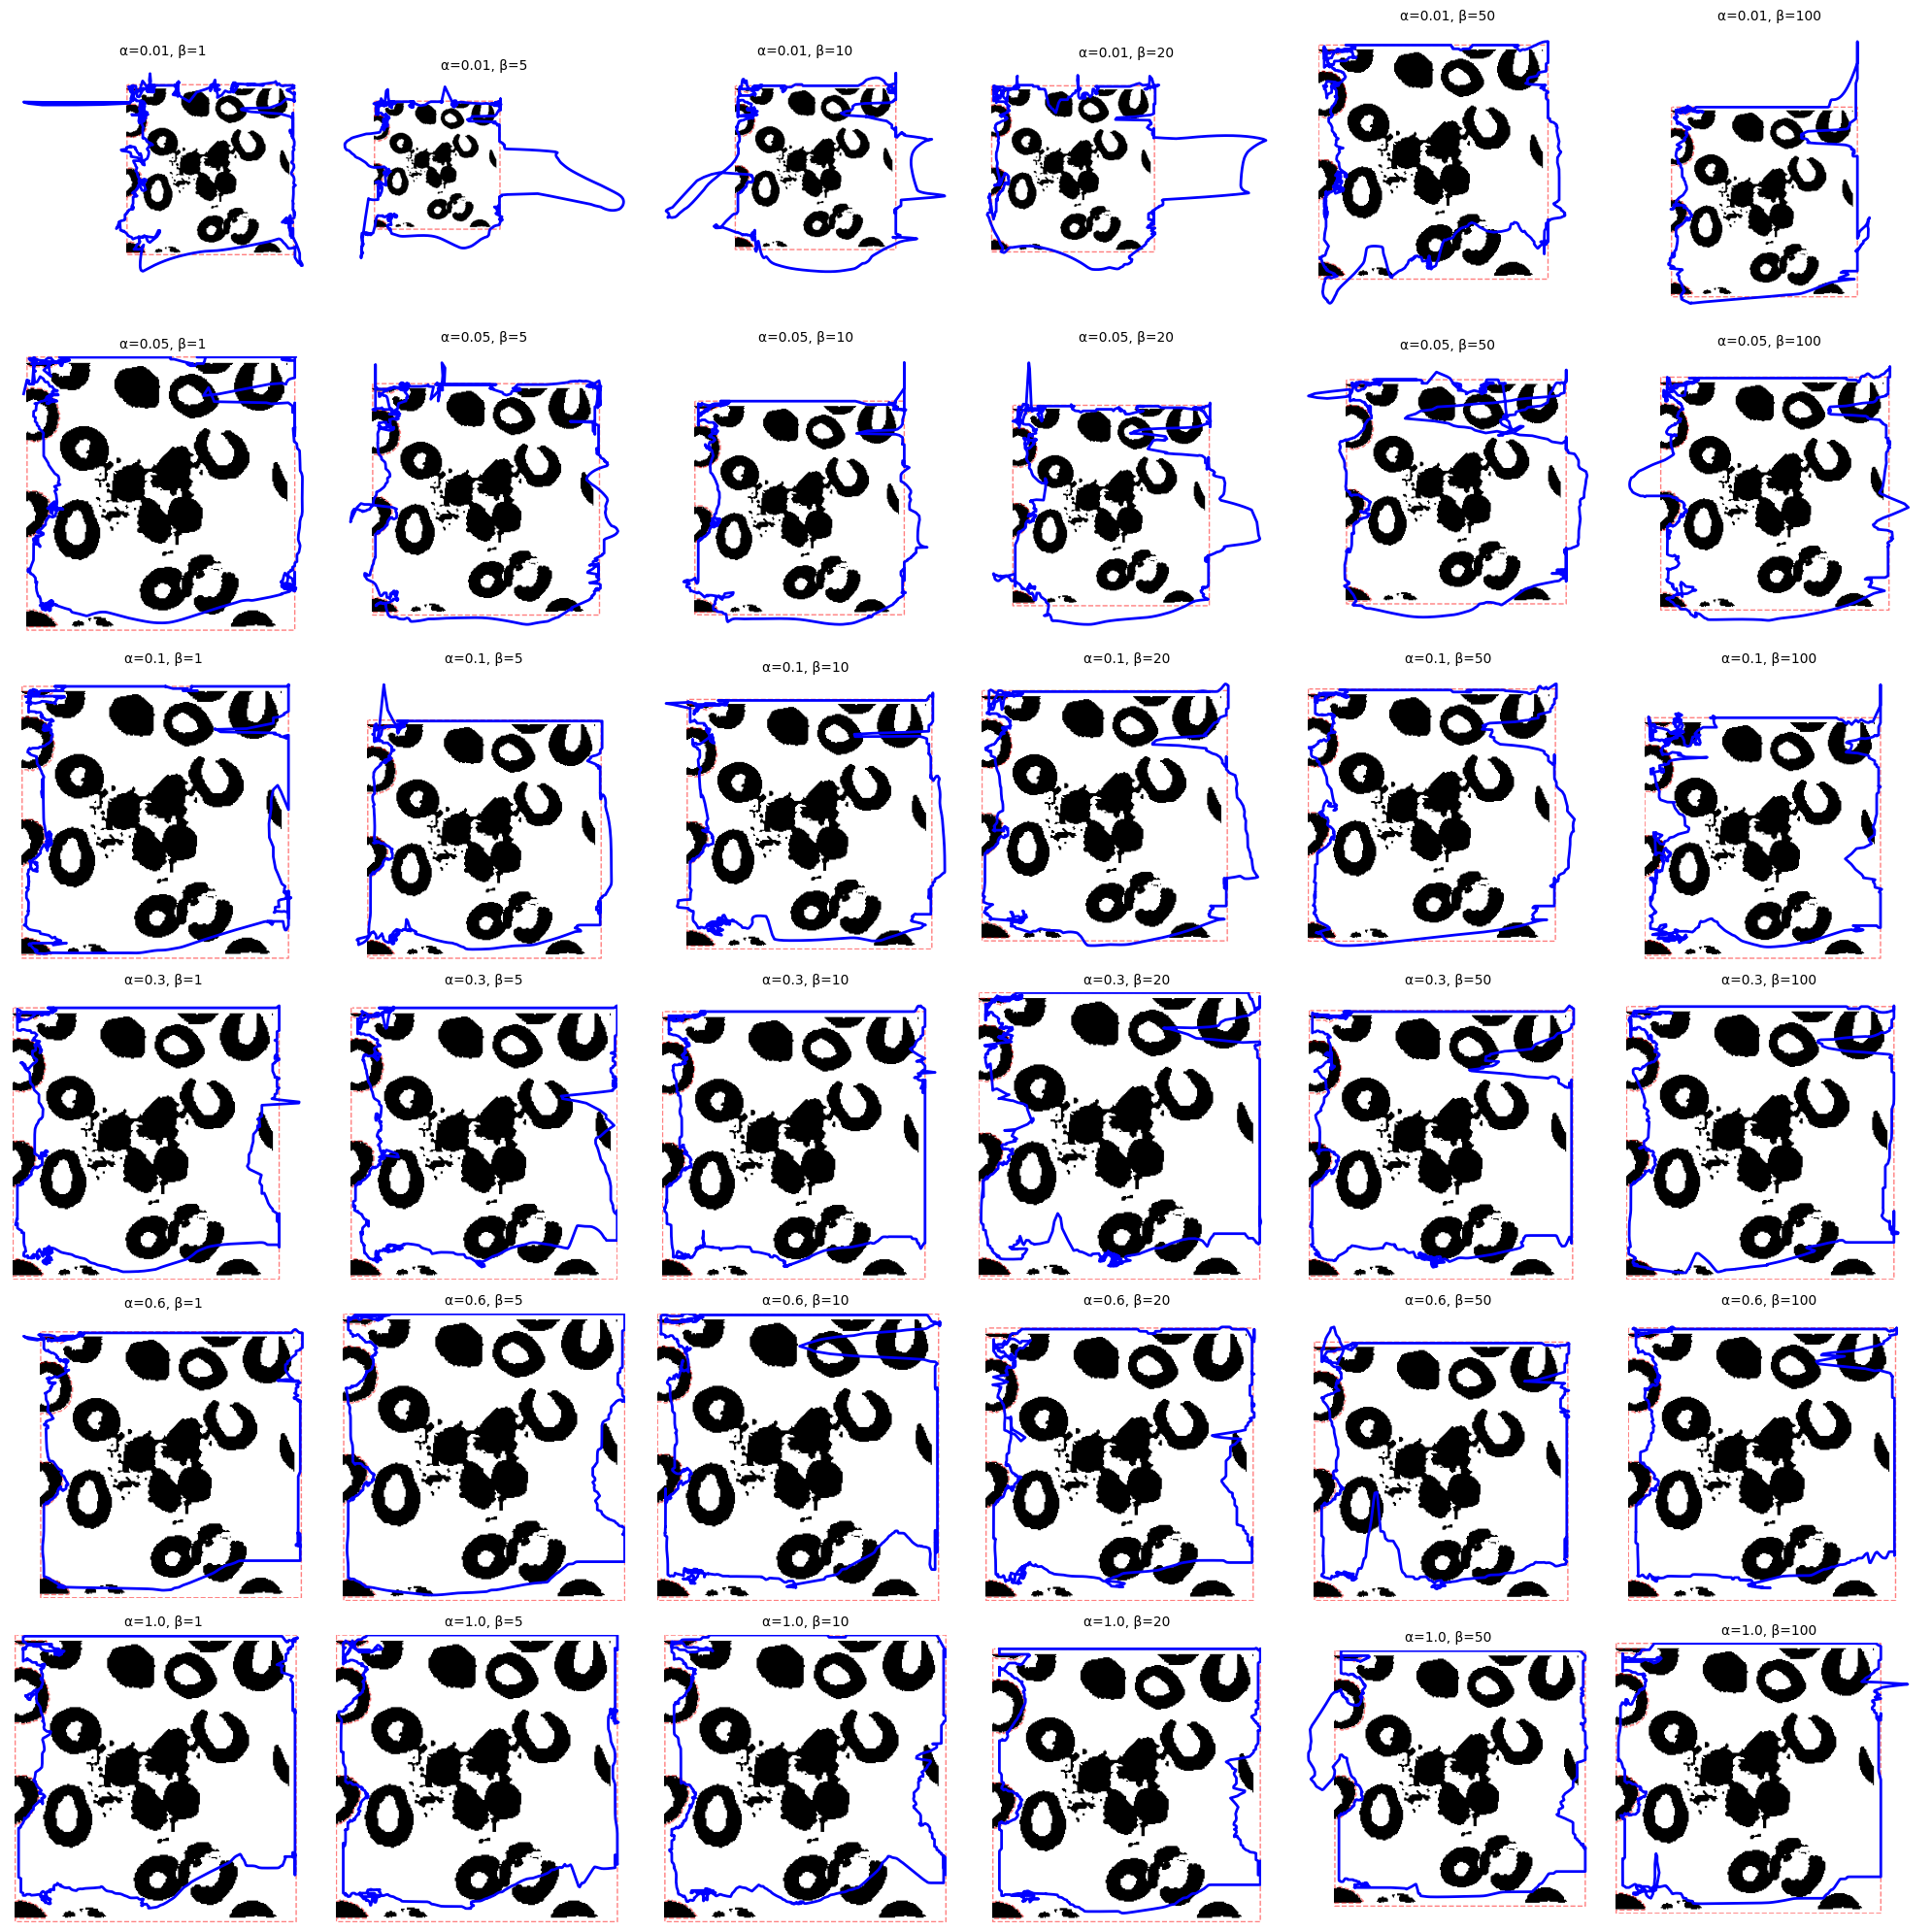

In [83]:
def test_snake_parameters(binary_img, init_contour, alpha_values, beta_values):
    fig, axes = plt.subplots(len(alpha_values), len(beta_values), figsize=(20, 20))
    
    for i, alpha in enumerate(alpha_values):
        for j, beta in enumerate(beta_values):
            snake = active_contour(binary_img, init_contour, alpha=alpha, beta=beta, gamma=0.001, w_line=-5, w_edge=0)
            
            axes[i, j].imshow(binary_img, cmap='gray')
            axes[i, j].plot(init_contour[:, 0], init_contour[:, 1], 'r--', linewidth=1, alpha=0.5)
            axes[i, j].plot(snake[:, 0], snake[:, 1], 'b-', linewidth=2)
            axes[i, j].set_title(f'α={alpha}, β={beta}', fontsize=10)
            axes[i, j].axis('off')
    
    plt.tight_layout()
    plt.show()

alpha_values = [0.01, 0.05, 0.1, 0.3, 0.6, 1.0]
beta_values = [1, 5, 10, 20, 50, 100]

test_snake_parameters(binary, init, alpha_values, beta_values)

nonoe of these seem good so i tried changing the binary threshhold

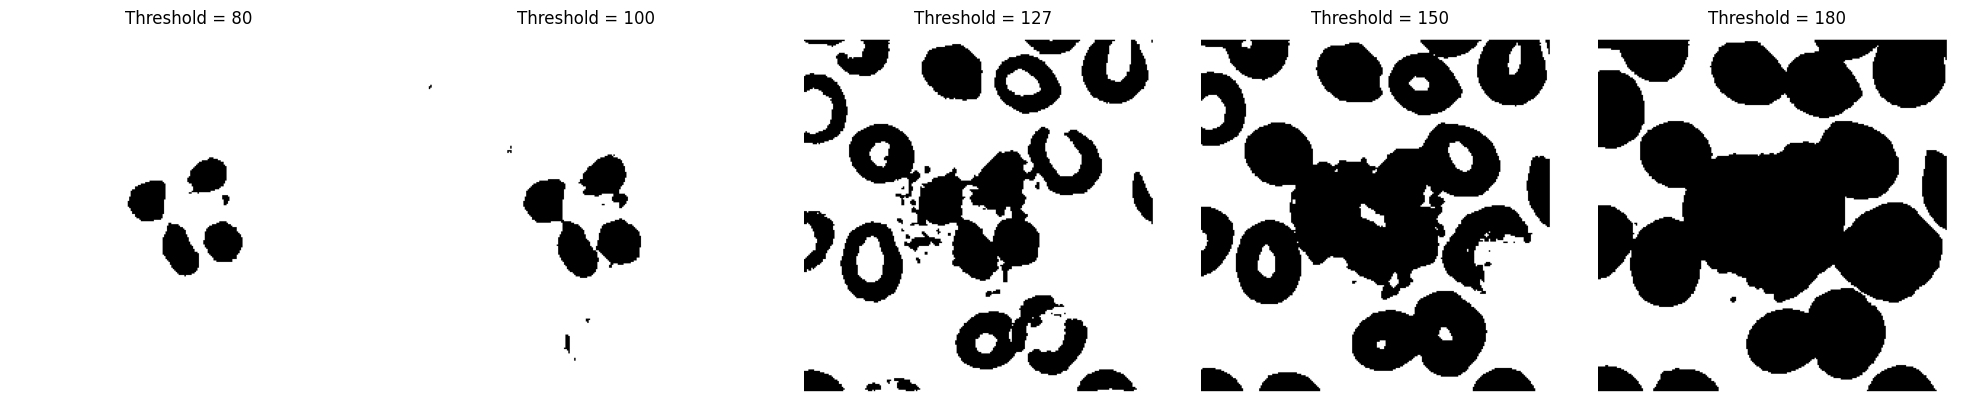

In [84]:
threshold_values = [80, 100, 127, 150, 180]

fig, axes = plt.subplots(1, len(threshold_values), figsize=(20, 4))

for idx, thresh in enumerate(threshold_values):
    binary_test = cv2.threshold(gray, thresh, 255, cv2.THRESH_BINARY)[1]
    axes[idx].imshow(binary_test, cmap='gray')
    axes[idx].set_title(f'Threshold = {thresh}', fontsize=12)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

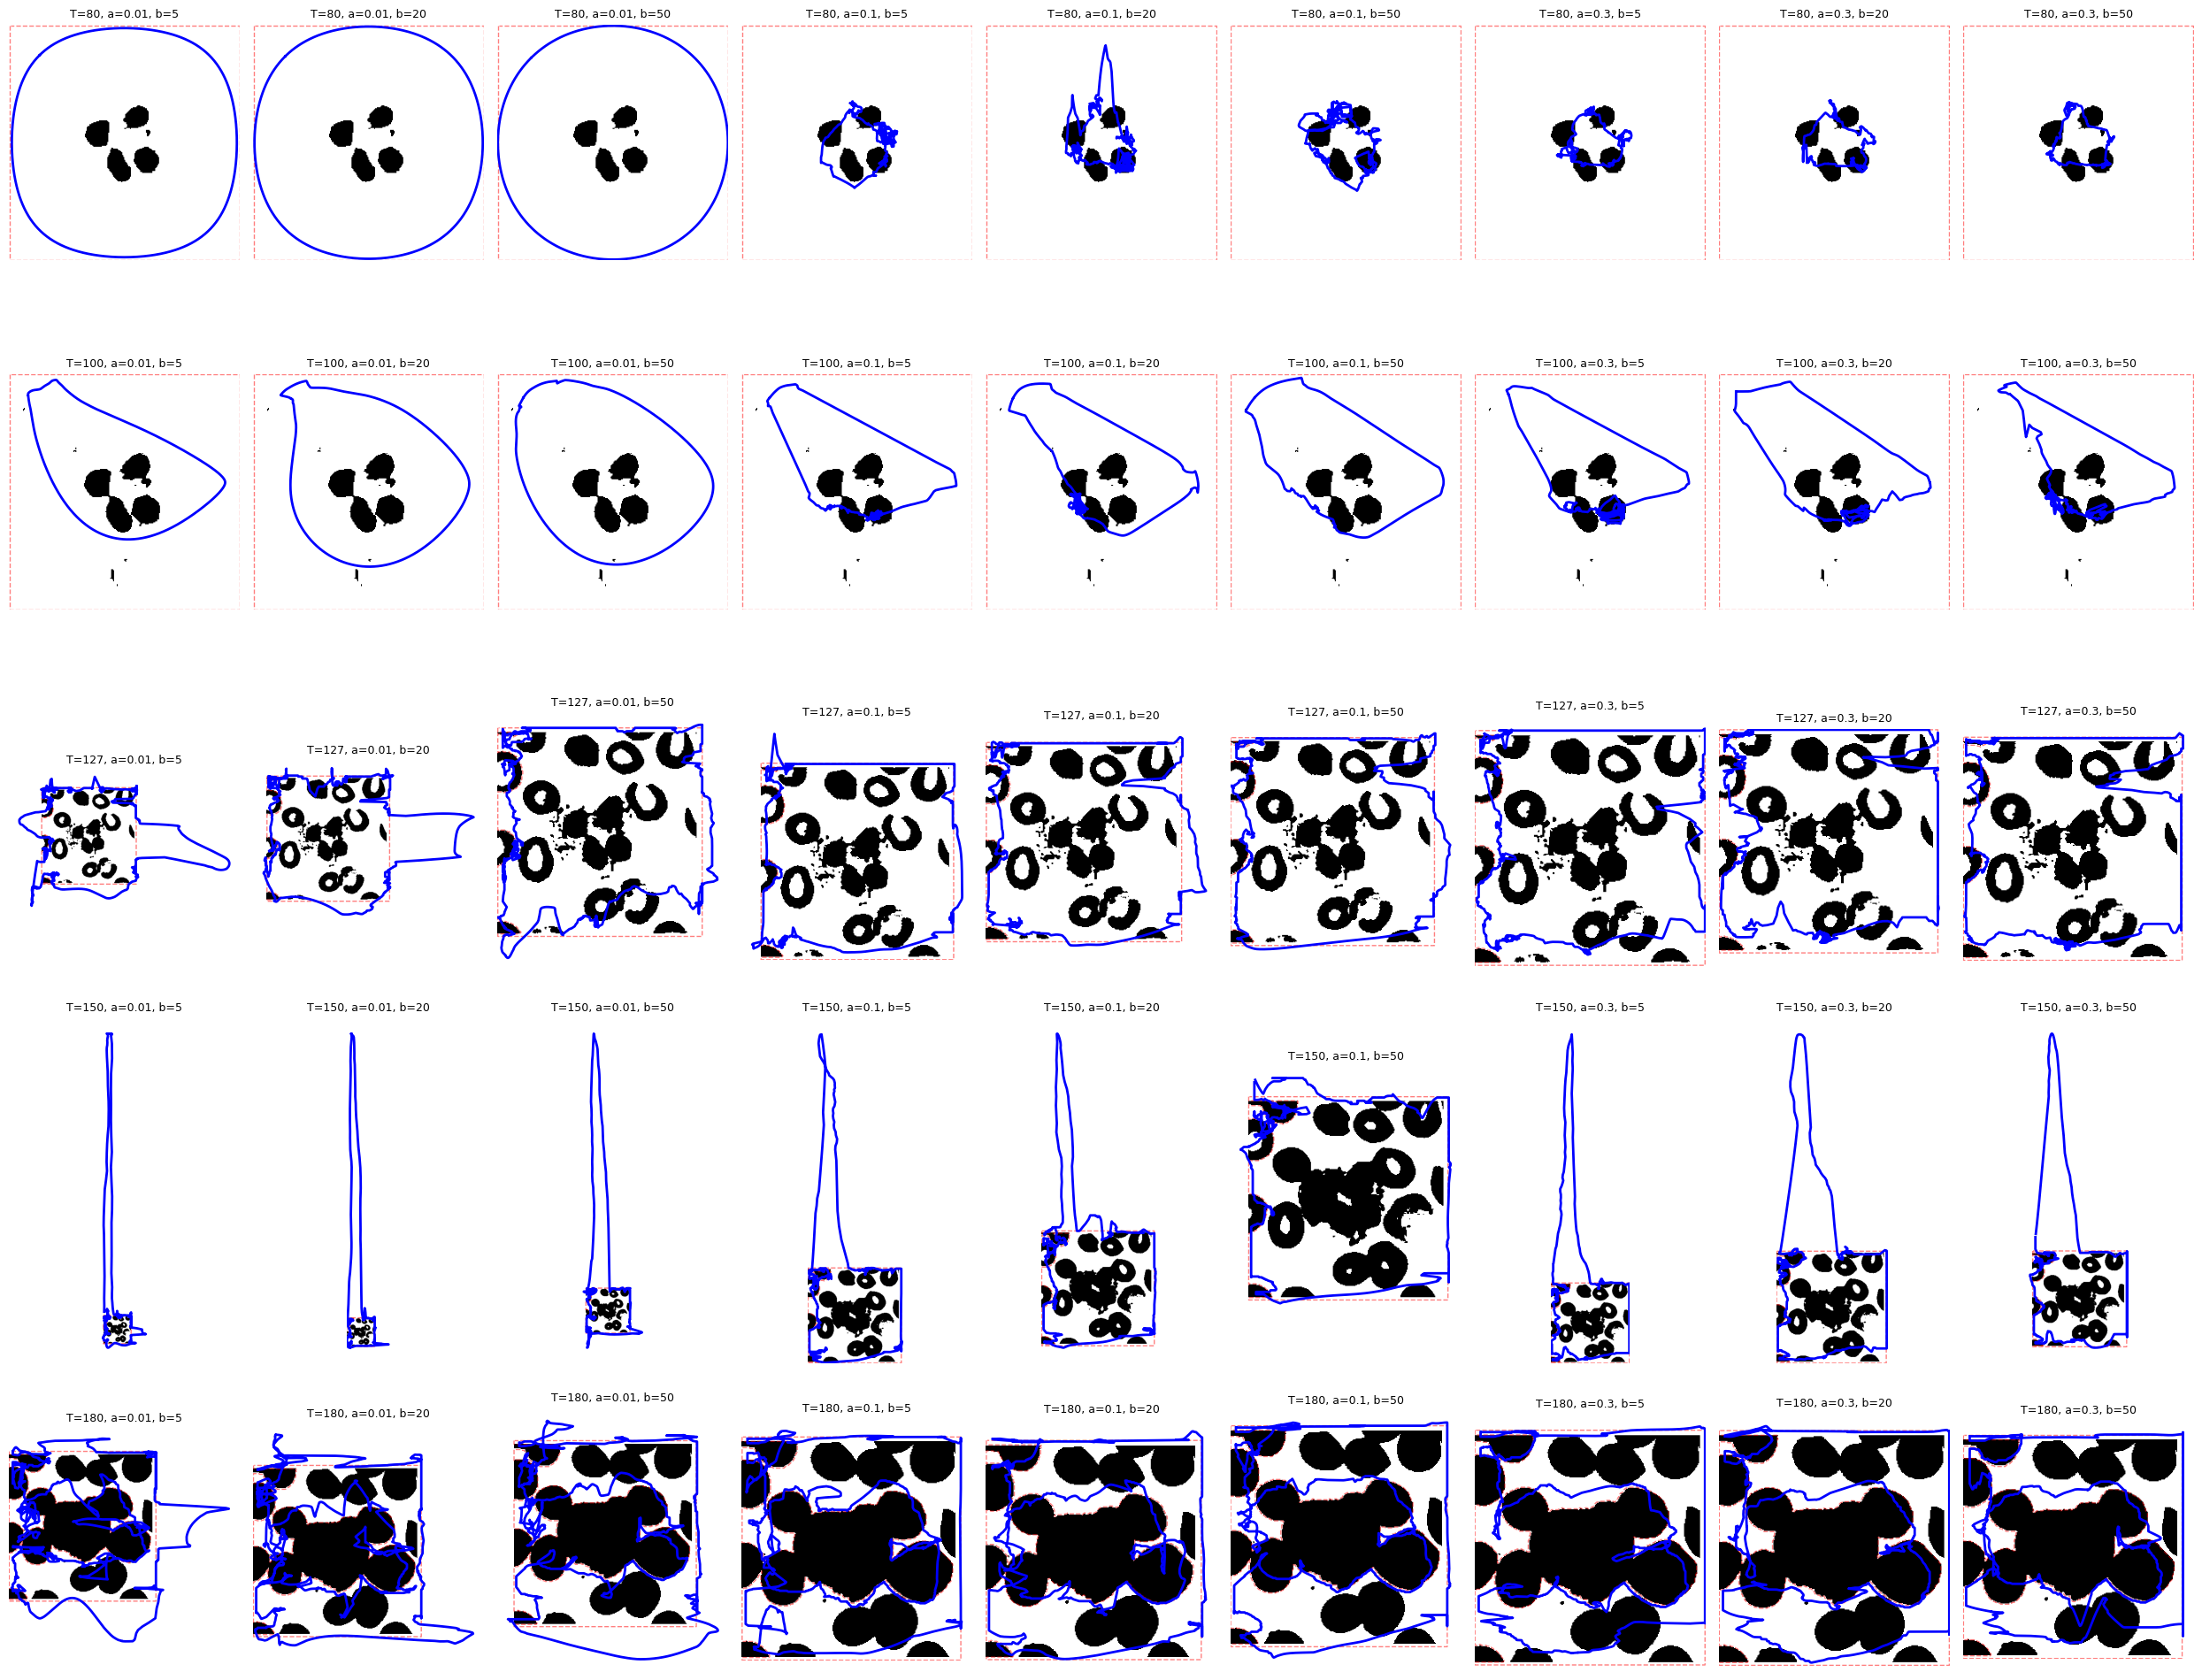

In [85]:
threshold_values = [80, 100, 127, 150, 180]
alpha_values = [0.01, 0.1, 0.3]
beta_values = [5, 20, 50]

fig, axes = plt.subplots(len(threshold_values), len(alpha_values) * len(beta_values), figsize=(25, 20))

for t_idx, thresh in enumerate(threshold_values):
    binary_test = cv2.threshold(gray, thresh, 255, cv2.THRESH_BINARY)[1]
    contours_test, _ = cv2.findContours(binary_test, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    
    if len(contours_test) > 0:
        largest_contour_test = max(contours_test, key=cv2.contourArea)
        init_test = np.squeeze(largest_contour_test).astype(float)
        
        col_idx = 0
        for alpha in alpha_values:
            for beta in beta_values:
                snake = active_contour(binary_test, init_test, alpha=alpha, beta=beta, gamma=0.001, w_line=-5, w_edge=0)
                
                axes[t_idx, col_idx].imshow(binary_test, cmap='gray')
                axes[t_idx, col_idx].plot(init_test[:, 0], init_test[:, 1], 'r--', linewidth=1, alpha=0.5)
                axes[t_idx, col_idx].plot(snake[:, 0], snake[:, 1], 'b-', linewidth=2)
                axes[t_idx, col_idx].set_title(f'T={thresh}, a={alpha}, b={beta}', fontsize=9)
                axes[t_idx, col_idx].axis('off')
                col_idx += 1

plt.tight_layout()
plt.show()